## Libraries

In [1]:
import pandas as pd
import numpy as np

%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df_grouped = pd.read_csv("processed_data/feature_engineering_grouped.csv")
df_grouped["date"] = pd.to_datetime(df_grouped["date"])

# Exploratory (all available years)

In [3]:
print("Here's the list of available municipalities")
print(sorted(df_grouped["name"].unique().tolist()))

while True:
    place = input("Choose a municipality: ")

    if place in df_grouped["name"].unique().tolist():
            print(f"You chose {place}")
            break
    else:
            print(place)
            print("Wrong input, try again")

Here's the list of available municipalities
['Albaredo per San Marco', 'Albosaggia', 'Andalo Valtellino', 'Aprica', 'Ardenno', 'Bema', 'Berbenno di Valtellina', 'Bianzone', 'Bormio', 'Buglio in Monte', 'Caiolo', 'Campodolcino', 'Caspoggio', "Castello dell'Acqua", 'Castione', 'Cataeggio', 'Cedrasco', 'Cepina', 'Cercino', 'Chiavenna', 'Chiesa in Valmalenco', 'Chiuro', 'Cino', 'Colorina', 'Dazio', 'Delebio', 'Dubino', 'Era', 'Fusine', 'Gerola Alta', 'Gordona', 'Grosio', 'Grosotto', 'Isolaccia', 'Lanzada', 'Livigno', 'Lovero', 'Mantello', 'Mazzo di Valtellina', 'Mello', 'Mese', 'Montagna in Valtellina', 'Morbegno', 'Novate Mezzola', 'Pedesina', 'Pianazzo', 'Piantedo', 'Piateda', 'Poggiridenti', 'Ponte in Valtellina', 'Postalesio', 'Prata Camportaccio', 'Prosto', 'Rasura', 'Regoledo', 'Rogolo', 'San Carlo', 'San Giacomo Filippo', 'San Nicolò', 'Sernio', 'Serone', 'Sirta', 'Sondalo', 'Sondrio', 'Spriana', 'Talamona', 'Tartano', 'Teglio', 'Tirano', 'Torre di Santa Maria', "Tovo di Sant'Agata"

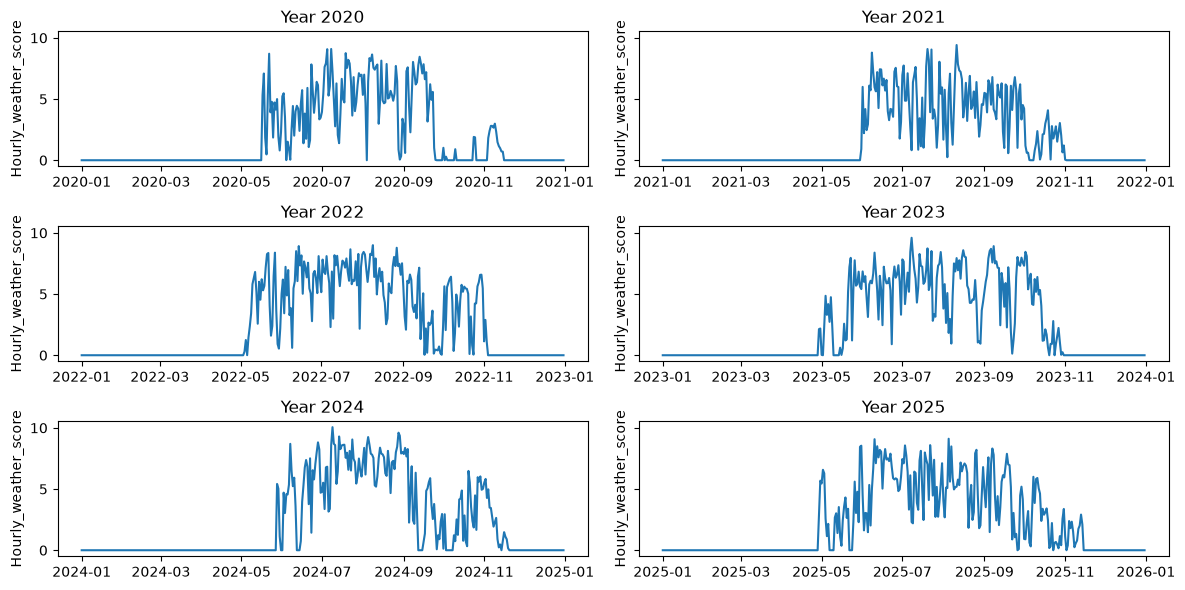

In [ ]:
years = df_grouped["date"].dt.year.unique().tolist()

fig, axes = plt.subplots(
    int(len(years)/2),
    2, 
    figsize=(12, 6),
    # sharex=True,
    sharey=True,
    squeeze=False   # axes will always be a bidimensional array, regardless of the available years
    )

for ax, year in zip(axes.flat, years):      # .flat allows to treat axes (bidimensional) as monodimensional
    data = df_grouped.loc[(df_grouped["date"].dt.year == year) & (df_grouped["name"] == place)]

    ax.plot(data["date"], data["Hourly_weather_score"])
    ax.set_title(f"Year {year}")
    ax.set_ylabel("Hourly_weather_score")

plt.tight_layout()
plt.show()

# Strategy (single year)

In [31]:
print("Here's the list of available years")
print(df_grouped["date"].dt.year.unique().tolist())
print("Here's the list of available municipalities")
print(sorted(df_grouped["name"].unique().tolist()))

while True:
    year = int(input("Choose a year: "))
    place = input("Choose a municipality: ")

    if year in df_grouped["date"].dt.year.unique().tolist():
        print(f"You chose {year}")
        if place in df_grouped["name"].unique().tolist():
            print(f"You chose {place}")
            break
        else:
                print(place)
                print("Wrong input, try again")
    else:
        print(year)
        print("Wrong input, try again")

Here's the list of available years
[2020, 2021, 2022, 2023, 2024, 2025]
Here's the list of available municipalities
['Albaredo per San Marco', 'Albosaggia', 'Andalo Valtellino', 'Aprica', 'Ardenno', 'Bema', 'Berbenno di Valtellina', 'Bianzone', 'Bormio', 'Buglio in Monte', 'Caiolo', 'Campodolcino', 'Caspoggio', "Castello dell'Acqua", 'Castione', 'Cataeggio', 'Cedrasco', 'Cepina', 'Cercino', 'Chiavenna', 'Chiesa in Valmalenco', 'Chiuro', 'Cino', 'Colorina', 'Dazio', 'Delebio', 'Dubino', 'Era', 'Fusine', 'Gerola Alta', 'Gordona', 'Grosio', 'Grosotto', 'Isolaccia', 'Lanzada', 'Livigno', 'Lovero', 'Mantello', 'Mazzo di Valtellina', 'Mello', 'Mese', 'Montagna in Valtellina', 'Morbegno', 'Novate Mezzola', 'Pedesina', 'Pianazzo', 'Piantedo', 'Piateda', 'Poggiridenti', 'Ponte in Valtellina', 'Postalesio', 'Prata Camportaccio', 'Prosto', 'Rasura', 'Regoledo', 'Rogolo', 'San Carlo', 'San Giacomo Filippo', 'San Nicolò', 'Sernio', 'Serone', 'Sirta', 'Sondalo', 'Sondrio', 'Spriana', 'Talamona', 'Ta

You chose 2024
You chose Piantedo


## Run-length analysis

In [32]:
data = df_grouped.loc[(df_grouped["date"].dt.year == year) & (df_grouped["name"] == place)]

Steps:
* active days
    * score > 0
    * it is possible a gap between active days (default = 1)
* groups of days (status active-inactive changes)
* dataframe with active-inactive, start, end, length

In [7]:
def get_runs(score, max_gap=1):

    active = score.fillna(0) > 0                        # active days = score > 0

    for _ in range(max_gap):                            # considering the max gap
        active = active | (                             # fills gaps of 1 day between active days
                active.shift(1, fill_value=False) &
                active.shift(-1, fill_value=False)
            )

    groups = active.ne(active.shift()).cumsum()         # separates consecutive runs in groups, defined when the status changes (ne.shift means not equal to the previous)

    runs = pd.DataFrame({
        "active": active,
        "group": groups
    }).groupby("group").agg(
        active=("active", "first"),                     # status of the group (active or inactive)
        start=("active", lambda x: x.index[0]),         # first date (date = index)
        end=("active", lambda x: x.index[-1]),          # last date (date = index)
        length=("active", "size")                       # number of observations
    )

    return runs

Steps: 
* calls previous function to get groups of active-inactive days
* active runs
    * length >= min (default = 5)
        * if there are no active days -> return None
        * start of the season = start of first active group
* inactive runs
    * length >= min (default = 7)
    * after season start 
        * if there are no inactive runs -> season end = last day with score > 0
        * if there are inactive runs -> season end = day before first inactive run
* "returns" of summer
    * active runs after the end of the season
    * IN THIS CASE, NO MINIMUM THRESHOLD IS DEFINED (EVEN A SINGLE DAY IS CLASSIFIED AS A RETURN)

In [ ]:
def identify_season(score, min_active=5, min_inactive=7, max_gap=1):

    runs = get_runs(score, max_gap=max_gap)

    active_runs = runs[                             # active sequences, with length >= threshold
        (runs["active"]) &
        (runs["length"] >= min_active)
    ]

    if active_runs.empty:
        return None

    start = active_runs.iloc[0]["start"]            # first date of the first active sequence

    inactive_runs = runs[                           # inactive runs, long enough, after the season start
        (~runs["active"]) &
        (runs["length"] >= min_inactive) &
        (runs["start"] > start)
    ]

    if inactive_runs.empty:
        end = score[score > 0].index.max()
    else:
        end = inactive_runs.iloc[0]["start"] - pd.Timedelta(days=1)       # day before the first date of the first inactive sequence

    returns = runs[                             # all active sequences after the end of the season
        (runs["active"]) &
        (runs["start"] > end)
    ]
    
    return {
        "start": start,
        "end": end,
        "returns": returns
    }

After a preliminary analysis, I noticed that the default parameters for identify season are not correct and need to be changed

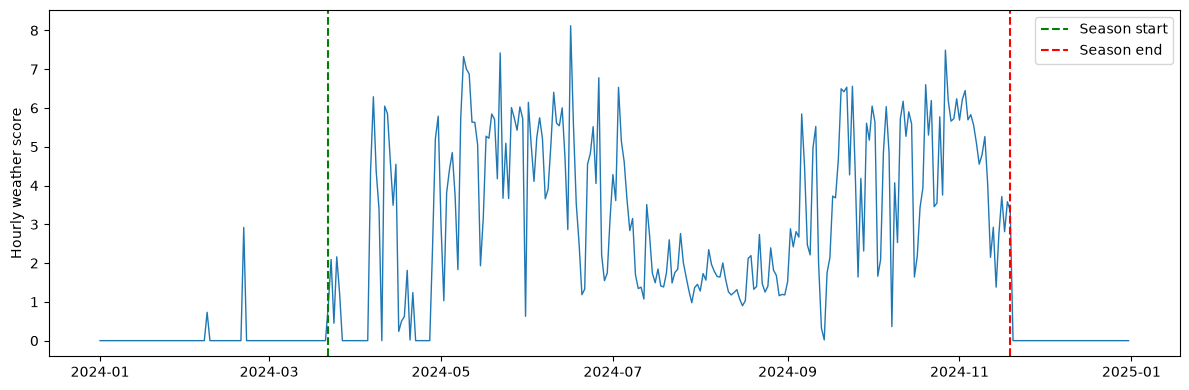

In [ ]:
result = identify_season(
    data.set_index("date")["Hourly_weather_score"],     # in the function get_runs I used lambda x: x.index[0], so the date needs to be set as index
    min_active=5,
    min_inactive=11,
    max_gap=1
)

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    data["date"],
    data["Hourly_weather_score"],
    linewidth=1
)

ax.axvline(
    result["start"],
    color="green",
    linestyle="--",
    label="Season start"
)

if result["end"] is not None:
    ax.axvline(
        result["end"],
        color="red",
        linestyle="--",
        label="Season end"
    )

for i, (_, run) in enumerate(result["returns"].iterrows()):

    ax.axvspan(
        run["start"],
        run["end"],
        color="orange",
        alpha=0.3,
        label="Summer returns" if i == 0 else None
    )

ax.set_ylabel("Hourly weather score")
ax.legend()
plt.tight_layout()
plt.show()

In [34]:
result

{'start': Timestamp('2024-03-22 00:00:00'),
 'end': Timestamp('2024-03-26 00:00:00'),
 'returns':        active      start        end  length
 group                                      
 8        True 2024-04-06 2024-04-21      16
 10       True 2024-04-28 2024-11-19     206}

The metrics for classifying municipalities are:
* season
    * start
    * end
    * duration
    * overall cumulative score
* returns
    * overall duration
    * last available date
    * number
    * longest duration
    * overall cumulative score

In [11]:
def display_results(result):
    season_start = result["start"]
    season_end = result["end"]
    
    if season_end is not None:
        season_duration = pd.Timedelta(season_end - season_start)
        season_cum_score = data.loc[data["date"].between(season_start, season_end)]["Hourly_weather_score"].sum()
    else:
        season_duration = None
        season_cum_score = data.loc[data["date"] >= season_start]["Hourly_weather_score"].sum()

    if len(result["returns"]) != 0:
        returns_duration = result["returns"]["length"].sum()
        returns_end = result["returns"].iloc[-1]["end"]
        returns_num = len(result["returns"])
        returns_max_duration = result["returns"]["length"].max()

        mask = [date for _, row in result["returns"].iterrows() 
                for date in pd.date_range(row["start"], row["end"], freq="D")]

        returns_cum_score = data.loc[data["date"].isin(mask)]["Hourly_weather_score"].sum()

    else:
            returns_duration = 0
            returns_end = pd.NaT
            returns_num = 0
            returns_max_duration = 0
            returns_cum_score = 0

    return {
        "season_start": season_start,
        "season_end": season_end,
        "season_duration": season_duration,
        "season_cum_score": season_cum_score,
        "returns_duration": returns_duration,
        "returns_end": returns_end,
        "returns_num": returns_num,
        "returns_max_duration": returns_max_duration,
        "returns_cum_score": returns_cum_score
    }

# Implementation (all years and municipalities)

In [37]:
intermediate_list = []

for municipality in (df_grouped["name"].unique().tolist()):
    for year in years:

        data = df_grouped.loc[(df_grouped["date"].dt.year == year) & (df_grouped["name"] == municipality)]
        result = identify_season(
            data.set_index("date")["Hourly_weather_score"],
            min_active=5,
            min_inactive=11,
            max_gap=1
        )

        (season_start, season_end, season_duration, season_cum_score, returns_duration, returns_end, returns_num, returns_max_duration, returns_cum_score) = display_results(result)
        
        intermediate_list.append({"municipality": municipality,
                             "year": year,
                             **display_results(result) # ** expands a dictionary inside another dictionary
                             })
        
final_df = pd.DataFrame(intermediate_list)

final_df

,municipality,year,season_start,season_end,season_duration,season_cum_score,returns_duration,returns_end,returns_num,returns_max_duration,returns_cum_score
0,Albaredo per San Marco,2020,2020-04-25,2020-11-28,217 days,561.506378,0,NaT,0,0,0.000000
1,Albaredo per San Marco,2021,2021-05-14,2021-10-31,170 days,523.871822,0,NaT,0,0,0.000000
2,Albaredo per San Marco,2022,2022-04-10,2022-11-19,223 days,699.567337,0,NaT,0,0,0.000000
3,Albaredo per San Marco,2023,2023-03-23,2023-10-30,221 days,707.894516,2,2023-11-24,1,2,1.171075
4,Albaredo per San Marco,2024,2024-04-30,2024-11-19,203 days,699.268043,0,NaT,0,0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...
457,Villa di Tirano,2021,2021-05-31,2021-11-01,154 days,586.644413,0,NaT,0,0,0.000000
458,Villa di Tirano,2022,2022-05-03,2022-11-03,184 days,682.690866,0,NaT,0,0,0.000000
459,Villa di Tirano,2023,2023-04-28,2023-10-30,185 days,715.739777,0,NaT,0,0,0.000000
460,Villa di Tirano,2024,2024-05-27,2024-11-19,176 days,614.817845,0,NaT,0,0,0.000000


In [48]:
final_df.to_csv("processed_data/feature_engineering_seasons.csv", index=False)

# Checking parameters (all years)

First, it is important to check for outliers, in order to identify problematic municipalities

<Axes: ylabel='season_duration'>

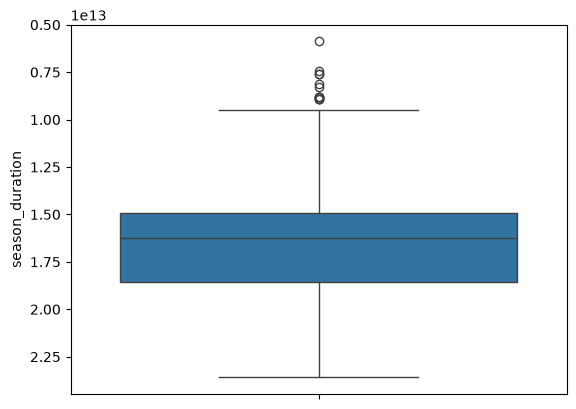

In [38]:
sns.boxplot(final_df["season_duration"])

A season should not last less than 2 months, so outliers could be detected in this way

In [39]:
final_df.loc[final_df["season_duration"] <= pd.Timedelta(days=60)]

,municipality,year,season_start,season_end,season_duration,season_cum_score,returns_duration,returns_end,returns_num,returns_max_duration,returns_cum_score


I also checked for long returns

In [40]:
final_df.loc[final_df["returns_duration"] >= 20]

,municipality,year,season_start,season_end,season_duration,season_cum_score,returns_duration,returns_end,returns_num,returns_max_duration,returns_cum_score
52,Bormio,2024,2024-07-01,2024-09-25,86 days,275.206172,26,2024-11-18,2,24,65.907300
114,Chiavenna,2020,2020-05-09,2020-10-25,169 days,566.036562,23,2020-11-30,2,14,77.696894
200,Isolaccia,2022,2022-06-01,2022-09-23,114 days,359.662242,21,2022-11-02,2,16,44.885377
202,Isolaccia,2024,2024-07-01,2024-09-27,88 days,336.920754,25,2024-11-17,3,22,61.230768
212,Livigno,2022,2022-06-02,2022-09-23,113 days,310.316854,20,2022-11-02,2,15,18.764848
214,Livigno,2024,2024-07-05,2024-09-11,68 days,301.184056,29,2024-11-16,4,22,31.575376
312,Prosto,2020,2020-05-09,2020-10-25,169 days,395.274711,23,2020-11-30,2,14,69.274772
323,Rasura,2025,2025-03-29,2025-11-17,233 days,783.398592,21,2025-12-23,3,13,11.583775
342,San Giacomo Filippo,2020,2020-05-09,2020-10-25,169 days,427.140062,23,2020-11-30,2,14,60.004054
350,San Nicolò,2022,2022-06-01,2022-09-23,114 days,326.582603,22,2022-11-03,2,16,50.851750


Then, we can visualize the problems

In [46]:
print("Here's the list of available municipalities")
print(sorted(df_grouped["name"].unique().tolist()))

while True:
    place = input("Choose a municipality: ")

    if place in df_grouped["name"].unique().tolist():
            print(f"You chose {place}")
            break
    else:
            print(place)
            print("Wrong input, try again")

Here's the list of available municipalities
['Albaredo per San Marco', 'Albosaggia', 'Andalo Valtellino', 'Aprica', 'Ardenno', 'Bema', 'Berbenno di Valtellina', 'Bianzone', 'Bormio', 'Buglio in Monte', 'Caiolo', 'Campodolcino', 'Caspoggio', "Castello dell'Acqua", 'Castione', 'Cataeggio', 'Cedrasco', 'Cepina', 'Cercino', 'Chiavenna', 'Chiesa in Valmalenco', 'Chiuro', 'Cino', 'Colorina', 'Dazio', 'Delebio', 'Dubino', 'Era', 'Fusine', 'Gerola Alta', 'Gordona', 'Grosio', 'Grosotto', 'Isolaccia', 'Lanzada', 'Livigno', 'Lovero', 'Mantello', 'Mazzo di Valtellina', 'Mello', 'Mese', 'Montagna in Valtellina', 'Morbegno', 'Novate Mezzola', 'Pedesina', 'Pianazzo', 'Piantedo', 'Piateda', 'Poggiridenti', 'Ponte in Valtellina', 'Postalesio', 'Prata Camportaccio', 'Prosto', 'Rasura', 'Regoledo', 'Rogolo', 'San Carlo', 'San Giacomo Filippo', 'San Nicolò', 'Sernio', 'Serone', 'Sirta', 'Sondalo', 'Sondrio', 'Spriana', 'Talamona', 'Tartano', 'Teglio', 'Tirano', 'Torre di Santa Maria', "Tovo di Sant'Agata"

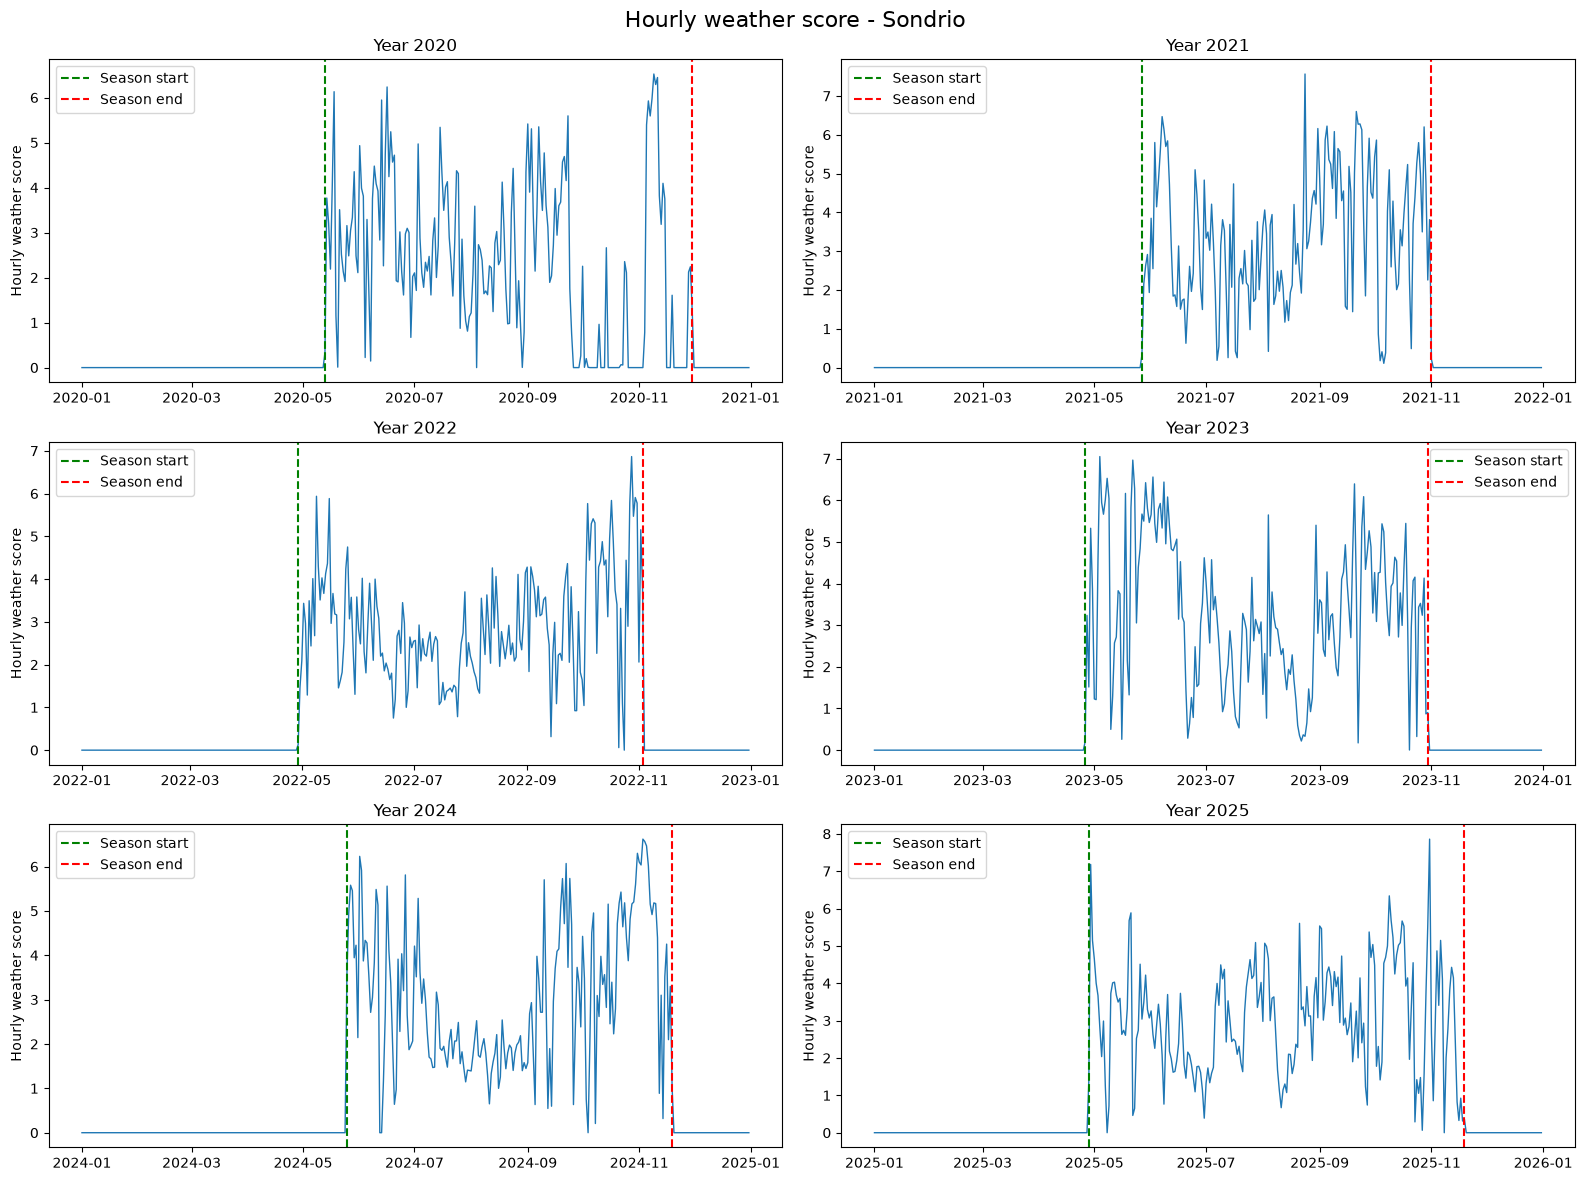

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(16, 12), sharex=False)

for ax, year in zip(axes.flat, years):

    data = df_grouped.loc[
        (df_grouped["date"].dt.year == year) &
        (df_grouped["name"] == place)
    ]

    result = identify_season(
        data.set_index("date")["Hourly_weather_score"],
        min_active=5,
        min_inactive=10,
        max_gap=1
    )

    # Time series
    ax.plot(
        data["date"],
        data["Hourly_weather_score"],
        linewidth=1
    )

    # Season start
    ax.axvline(
        result["start"],
        color="green",
        linestyle="--",
        label="Season start"
    )

    # Season end
    if result["end"] is not None:
        ax.axvline(
            result["end"],
            color="red",
            linestyle="--",
            label="Season end"
        )

    # Summer returns
    for i, (_, run) in enumerate(result["returns"].iterrows()):

        ax.axvspan(
            run["start"],
            run["end"],
            color="orange",
            alpha=0.3,
            label="Summer returns" if i == 0 else None
        )

    ax.set_title(f"Year {year}")
    ax.set_ylabel("Hourly weather score")
    ax.legend()

fig.suptitle(f"Hourly weather score - {place}", fontsize=16)

plt.tight_layout()
plt.show()

In [43]:
final_df.loc[final_df["municipality"] == place]

,municipality,year,season_start,season_end,season_duration,season_cum_score,returns_duration,returns_end,returns_num,returns_max_duration,returns_cum_score
342,San Giacomo Filippo,2020,2020-05-09,2020-10-25,169 days,427.140062,23,2020-11-30,2,14,60.004054
343,San Giacomo Filippo,2021,2021-05-31,2021-10-31,153 days,453.547833,0,NaT,0,0,0.000000
344,San Giacomo Filippo,2022,2022-04-28,2022-11-13,199 days,578.015040,0,NaT,0,0,0.000000
345,San Giacomo Filippo,2023,2023-04-27,2023-10-30,186 days,579.046787,0,NaT,0,0,0.000000
346,San Giacomo Filippo,2024,2024-05-25,2024-11-19,178 days,497.896198,0,NaT,0,0,0.000000
347,San Giacomo Filippo,2025,2025-04-26,2025-12-24,242 days,554.318259,0,NaT,0,0,0.000000


Then I can try again to run the code and see the output with different parameters